# Gradient boosting (R3)

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

This is our gradient boosting baseline for both tasks: predicting the maths score (regression) and flagging students below Level 2 (classification). We use scikit-learn's `HistGradientBoostingClassifier` and `HistGradientBoostingRegressor` on the 17 predictors, tune two settings on PV1, check that the 100-tree cap is high enough, then run all 10 plausible values on the 5 school folds and combine them with Rubin's rules. At the end we split the same test predictions by system.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_hgb_params.json` |
| `../data/clean/columns.json` | `outputs/ahmed_hgb_results.csv` |
| `../data/clean/folds.csv` | `outputs/ahmed_hgb_by_system.csv` |
| | `outputs/figures/ahmed_hgb_by_system.png` |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             root_mean_squared_error, mean_absolute_error, r2_score)

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
PVS = range(1, 11)
SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# no reading or science scores, no plausible values among the features
assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in FEATURES)
X = df[FEATURES]
print(X.shape, "| blanks left in:", int(X.isna().sum().sum()))
print("share below Level 2 (PV1, SENWT):", round(np.average(df["BELOW_L2_PV1"], weights=w), 3))

(61775, 17) | blanks left in: 124267
share below Level 2 (PV1, SENWT): 0.7


Gradient boosting handles blanks itself (it learns which side of each split they go to), so we pass the 17 raw predictors with NaN left in. No imputer, no scaler, and no `_missing` flags, since the trees already see where the blanks are.

# 1.1) The loop
One function runs a model on the chosen plausible values and the 5 school folds. It returns the fold scores and the test predictions, so the per-system results in section 6 reuse them with no refit. Training uses the normalised `SENWT` weights, and for classification we also multiply by balanced class weights so the 70% below Level 2 doesn't swamp the model. All metrics use `SENWT` on the test rows.

In [2]:
def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "pr_auc": average_precision_score(y, p, sample_weight=sw),
                "balanced_acc": balanced_accuracy_score(y, p > 0.5, sample_weight=sw),
                "recall_below": recall_score(y, p > 0.5, pos_label=1, sample_weight=sw),
                "recall_above": recall_score(y, p > 0.5, pos_label=0, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "mae": mean_absolute_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def run(task, params, pvs):
    rows, preds = [], {}
    for pv in pvs:
        y = target(task, pv)
        pred = pd.Series(np.nan, index=df.index)
        for k in range(5):
            train, test = df["fold"] != k, df["fold"] == k
            if task == "classification":
                model = HistGradientBoostingClassifier(**params, random_state=0)
                model.fit(X[train], y[train], sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
                pred[test] = model.predict_proba(X[test])[:, 1]
            else:
                model = HistGradientBoostingRegressor(**params, random_state=0)
                model.fit(X[train], y[train], sample_weight=w[train])
                pred[test] = model.predict(X[test])
            rows.append({"pv": pv, "fold": k, "trees": model.n_iter_, **score(task, y[test], pred[test], w[test])})
        preds[pv] = pred
    return pd.DataFrame(rows), preds


def rubin(res):
    # trees is a count from run, not a metric
    res = res.drop(columns=["fold", "trees"], errors="ignore")
    per_pv = res.groupby("pv").mean()
    within = res.groupby("pv").var().mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})

`rubin` is the combining step from `NEXT_STEPS.md`: the score is the mean over plausible values of the fold mean, and the standard error adds the fold-to-fold noise to the PV-to-PV noise.

# 2) Tuning on PV1
A small grid: two learning rates and three tree sizes (`max_leaf_nodes`), 6 settings per task, scored on PV1 with the same 5 folds. We pick by ROC-AUC for classification and RMSE for regression. With this many rows scikit-learn turns on early stopping by itself (10% of the training rows held back), so it can stop before the default cap of `max_iter=100` trees. Whether that cap is high enough is checked in 2.1.

In [3]:
GRID = [{"learning_rate": lr, "max_leaf_nodes": leaves} for lr in [0.05, 0.1] for leaves in [15, 31, 63]]

tuning = []
for params in GRID:
    clf_res, _ = run("classification", params, [1])
    reg_res, _ = run("regression", params, [1])
    tuning.append({**params, "roc_auc": clf_res["roc_auc"].mean(), "rmse": reg_res["rmse"].mean()})
tuning = pd.DataFrame(tuning)
tuning.round(4)

,learning_rate,max_leaf_nodes,roc_auc,rmse
0,0.05,15,0.8172,61.3015
1,0.05,31,0.8179,61.0444
2,0.05,63,0.8167,60.9491
3,0.10,15,0.8178,61.0700
4,0.10,31,0.8167,60.9568
5,0.10,63,0.8147,61.1015


In [4]:
best = {"classification": GRID[tuning["roc_auc"].idxmax()],
        "regression": GRID[tuning["rmse"].idxmin()]}
(OUT / "ahmed_hgb_params.json").write_text(json.dumps(best, indent=2), encoding="utf-8")
best

{'classification': {'learning_rate': 0.05, 'max_leaf_nodes': 31},
 'regression': {'learning_rate': 0.05, 'max_leaf_nodes': 63}}

> **Note:** the six settings land close together: ROC-AUC goes from 0.815 to 0.818 and RMSE from 60.95 to 61.30 points, so the choice matters little. The winners above are saved to `outputs/ahmed_hgb_params.json`, and the ablations notebook reads them from there.

# 2.1) Is 100 trees enough?
If early stopping never triggers, the model stops at the cap and not because the held-back rows stopped improving. So we rerun each winner on PV1 with `max_iter` at 100 and at 1000, and look at how many trees it actually used (`n_iter_`, mean over the 5 folds). The score is ROC-AUC for classification and RMSE for regression.

In [5]:
check = []
for task, metric in [("classification", "roc_auc"), ("regression", "rmse")]:
    for max_iter in [100, 1000]:
        res, _ = run(task, {**best[task], "max_iter": max_iter}, [1])
        check.append({"task": task, "max_iter": max_iter, "trees": res["trees"].mean(), "score": res[metric].mean()})
pd.DataFrame(check).round(4)

,task,max_iter,trees,score
0,classification,100,100.0,0.8179
1,classification,1000,191.0,0.8178
2,regression,100,100.0,60.9491
3,regression,1000,202.2,60.9304


> **Note:** with the cap at 100 both models use all 100 trees in every fold (the mean can only be 100 if each fold hits the cap), so early stopping never triggers. With the cap at 1000 they stop by themselves at about 190 to 200 trees (191 for classification, 202 for regression), and the score does not move: ROC-AUC 0.8179 at 100 and 0.8178 at 1000, RMSE 60.95 and 60.93 points. More trees buy nothing, so we keep 100.

# 3) Classification: below Level 2, all 10 PVs

In [6]:
clf_res, clf_preds = run("classification", best["classification"], PVS)
rubin(clf_res).round(3)

,score,se
roc_auc,0.819,0.004
pr_auc,0.903,0.002
balanced_acc,0.735,0.004
recall_below,0.823,0.004
recall_above,0.647,0.009


> **Note:** over all 10 PVs the ROC-AUC is 0.819 (se 0.004) and the PR-AUC 0.903. At the 0.5 threshold the balanced accuracy is 0.735 (se 0.004), with 0.823 of the students below Level 2 caught and 0.647 of those above it correctly left out (se 0.009). We show recall for both classes because with 70% below Level 2 a model can look good by only catching the majority.

# 4) Regression: maths score, all 10 PVs

In [7]:
reg_res, reg_preds = run("regression", best["regression"], PVS)
rubin(reg_res).round(3)

,score,se
rmse,60.750,0.328
mae,47.675,0.276
r2,0.428,0.012


> **Note:** the RMSE is 60.75 points (se 0.33), the MAE 47.7 and R² 0.428 (se 0.012), so the 17 predictors explain a bit over 40% of the variance in maths.

# 5) Results table
Both tasks in one long table, the same shape as the other model notebooks, so they can be stacked later.

In [8]:
results = pd.concat([rubin(clf_res).assign(task="classification"),
                     rubin(reg_res).assign(task="regression")])
results = results.rename_axis("metric").reset_index().assign(model="gradient_boosting")
results = results[["model", "task", "metric", "score", "se"]]
results.to_csv(OUT / "ahmed_hgb_results.csv", index=False)
results.round(3)

,model,task,metric,score,se
0,gradient_boosting,classification,roc_auc,0.819,0.004
1,gradient_boosting,classification,pr_auc,0.903,0.002
2,gradient_boosting,classification,balanced_acc,0.735,0.004
3,gradient_boosting,classification,recall_below,0.823,0.004
4,gradient_boosting,classification,recall_above,0.647,0.009
5,gradient_boosting,regression,rmse,60.750,0.328
6,gradient_boosting,regression,mae,47.675,0.276
7,gradient_boosting,regression,r2,0.428,0.012


> **Note:** every pooled se is small next to its score. Among the classification metrics the largest se is 0.009 (recall above Level 2), and for the maths score the RMSE se is 0.33 points, so the noise from the plausible values and the folds barely moves the pooled results.

# 6) Results per system
We split the test predictions from sections 3 and 4 by system, so nothing is refitted. Inside one system we weight with `W_FSTUWT`, the usual PISA student weight, since `SENWT` only matters when systems are pooled. The combining over PVs and folds is the same as above.

In [9]:
rows = []
for task, preds in [("classification", clf_preds), ("regression", reg_preds)]:
    for pv in PVS:
        y = target(task, pv)
        for k in range(5):
            for cnt in SYSTEMS:
                m = (df["fold"] == k) & (df["CNT"] == cnt)
                rows.append({"task": task, "system": cnt, "pv": pv, "fold": k,
                             **score(task, y[m], preds[pv][m], df.loc[m, "W_FSTUWT"])})
per_fold = pd.DataFrame(rows)

by_system = []
# dropna keeps only the metric columns of that task
for (task, cnt), d in per_fold.groupby(["task", "system"]):
    r = rubin(d.drop(columns=["task", "system"]).dropna(axis=1, how="all"))
    by_system.append(r.rename_axis("metric").reset_index().assign(task=task, system=cnt))
by_system = pd.concat(by_system).assign(model="gradient_boosting")
by_system = by_system[["model", "task", "system", "metric", "score", "se"]]
by_system.to_csv(OUT / "ahmed_hgb_by_system.csv", index=False)
by_system.pivot_table(index="system", columns="metric", values="score").loc[SYSTEMS].round(3)

metric,balanced_acc,mae,pr_auc,r2,recall_above,recall_below,rmse,roc_auc
system,,,,,,,,
ARE,0.724,59.066,0.810,0.460,0.857,0.590,74.372,0.824
SAU,0.660,46.155,0.850,0.203,0.553,0.767,58.509,0.726
QAT,0.733,52.387,0.836,0.429,0.765,0.702,66.322,0.814
JOR,0.678,43.050,0.934,0.222,0.475,0.880,54.270,0.771
MAR,0.655,41.384,0.945,0.296,0.372,0.937,52.357,0.809
PSE,0.662,43.868,0.924,0.292,0.399,0.924,55.342,0.783


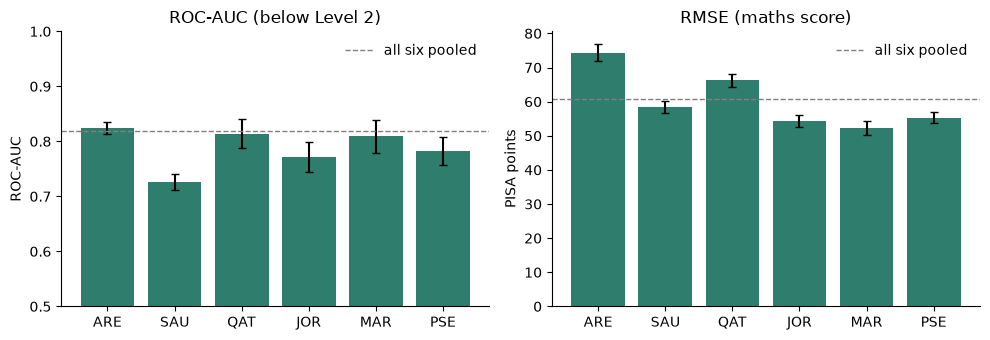

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
pooled = results.set_index("metric")["score"]
titles = {"roc_auc": "ROC-AUC (below Level 2)", "rmse": "RMSE (maths score)"}
for ax, metric in zip(axes, ["roc_auc", "rmse"]):
    d = by_system[by_system["metric"] == metric].set_index("system").loc[SYSTEMS]
    ax.bar(SYSTEMS, d["score"], yerr=1.96 * d["se"], color="#2F7D6D", capsize=3)
    ax.axhline(pooled[metric], color="grey", ls="--", lw=1, label="all six pooled")
    ax.set_title(titles[metric])
    ax.legend(frameon=False)
axes[0].set_ylim(0.5, 1)
axes[0].set_ylabel("ROC-AUC")
axes[1].set_ylabel("PISA points")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_hgb_by_system.png", bbox_inches="tight", dpi=150)
plt.show()

To read the per-system R² and RMSE we also need the spread of the maths score inside each system (PV1, weighted the same way).

In [11]:
sd = {cnt: np.sqrt(np.cov(d["PV1MATH"], aweights=d["W_FSTUWT"])) for cnt, d in df.groupby("CNT")}
sd["pooled"] = np.sqrt(np.cov(df["PV1MATH"], aweights=df["SENWT"]))
pd.Series(sd)[SYSTEMS + ["pooled"]].round(1).rename("sd_PV1MATH")

ARE       102.0
SAU        64.9
QAT        88.3
JOR        62.3
MAR        63.1
PSE        66.3
pooled     80.7
Name: sd_PV1MATH, dtype: float64

> **Note:** bars are the per-system scores with 95% intervals (1.96 se), and the dashed line is the pooled score from section 5. The per-system se behind the error bars are in `outputs/ahmed_hgb_by_system.csv`. They are larger than the pooled ones (0.006 to 0.015 for ROC-AUC, 0.8 to 1.2 points for RMSE), so only the bigger gaps between systems are clear. ARE (0.824), QAT (0.814) and MAR (0.809) are within the noise of the pooled ROC-AUC of 0.819, while PSE (0.783), JOR (0.771) and SAU (0.726) are clearly lower. RMSE follows the spread of the scores: ARE (74.4) and QAT (66.3) have the widest spread (SD 102 and 88 against 81 pooled) and the largest errors, but also the highest R² (0.460 and 0.429). The other four have an SD of 62 to 66, RMSE of 52 to 59 and R² of only 0.20 to 0.30. In MAR, PSE and JOR the model catches 0.88 or more of the students below Level 2 but correctly leaves out only 0.37 to 0.48 of those above it, so at the 0.5 threshold it flags most students there. In ARE it is the other way round: the model catches only 0.59 of the students below Level 2 and correctly leaves out 0.86 of those above. So one threshold for all six systems is lopsided inside most of them, which we follow up in `ahmed_country_immigrant.ipynb`.

# 7) Summary

- Gradient boosting on the 17 raw predictors, tuned on PV1 with a 6-setting grid, then run on all 10 PVs and 5 school folds. It picked a learning rate of 0.05 with 31 leaves for classification and 63 for regression (`outputs/ahmed_hgb_params.json`).
- The 100-tree cap is enough. With a cap of 1000 the models stop by themselves at 191 and 202 trees on average, and the score stays the same (ROC-AUC 0.8179 at 100 and 0.8178 at 1000, RMSE 60.95 and 60.93 points).
- Pooled, below Level 2: ROC-AUC 0.819 (se 0.004), balanced accuracy 0.735 (se 0.004), recall 0.823 below and 0.647 above Level 2. Maths score: RMSE 60.75 points (se 0.33), R² 0.428 (se 0.012). All in `outputs/ahmed_hgb_results.csv`, in the same long format as the other model notebooks.
- Per system (weighted with `W_FSTUWT`), ROC-AUC goes from 0.726 (SAU) to 0.824 (ARE) and RMSE from 52.4 (MAR) to 74.4 (ARE). PSE, JOR and SAU are clearly below the pooled ROC-AUC. At the 0.5 threshold the model flags most students in MAR, PSE and JOR but misses many below Level 2 in ARE (it catches only 0.59 of them). The scores are in `outputs/ahmed_hgb_by_system.csv` and the figure above.

Next: `ahmed_ablations.ipynb` (drop each factor group in turn), `../04_neural-networks/ahmed_mlp.ipynb` (MLP compared with this model) and `ahmed_country_immigrant.ipynb` (whether to add country or immigrant status, and a flag balanced inside each system).